# Classificação de risco de crédito: previsão de inadimplência

**Objetivo.** Comparar Naive Bayes Gaussiano, Árvore de Decisão e Random Forest, cada um em baseline e versão ajustada, para prever `Loan_Status`. A classe positiva é `Default` (inadimplência).

> **Origem dos dados:** [Chaitanya Jamble, Realistic Credit Scoring & Loan Default Prediction (Kaggle)](https://www.kaggle.com/datasets/chaitanyajamble/realistic-credit-scoring-and-loan-default-prediction). O projeto inclui uma licença CC0, mas não documenta o método de geração nem a representatividade dos registros; esses pontos permanecem como limitações.

## 1. Ambiente e reprodutibilidade

Execute as células em ordem, a partir da raiz do projeto ou desta pasta. A busca abaixo permite ambos os locais.

In [1]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, classification_report, ConfusionMatrixDisplay,
    f1_score, precision_score, recall_score, roc_auc_score, RocCurveDisplay,
)
from sklearn.model_selection import (
    GridSearchCV, StratifiedKFold, cross_validate, train_test_split,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree

SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_columns', None)
DATA_PATH = next(p for p in [Path('data/realistic_credit_scoring_dataset-1.csv'), Path('../data/realistic_credit_scoring_dataset-1.csv')] if p.exists())
print(f'pandas {pd.__version__} | NumPy {np.__version__} | scikit-learn {sklearn.__version__}')
print('Base:', DATA_PATH)

pandas 2.3.3 | NumPy 2.5.3 | scikit-learn 1.9.1
Base: ../data/realistic_credit_scoring_dataset-1.csv


## 2. Carregamento e análise exploratória

`Default_Probability` tem correlação de aproximadamente 0,75 com o alvo e domina a importância da árvore (cerca de 99,7% no teste exploratório). Como a documentação local não esclarece quando nem como esse atributo foi calculado, ele é excluído dos preditores para reduzir o risco de vazamento. Se a fonte confirmar que é um atributo independente, disponível antes da decisão, a equipe pode incluí-lo em uma análise de sensibilidade.

In [2]:
df = pd.read_csv(DATA_PATH)
TARGET = 'Loan_Status'
print('Dimensões:', df.shape)
display(df.head())
display(df.dtypes.rename('tipo').to_frame())
print('Duplicatas:', df.duplicated().sum())
print('Valores ausentes por coluna:')
display(df.isna().sum().rename('ausentes').to_frame())
print('Distribuição da classe:')
display(df[TARGET].value_counts(dropna=False).rename('quantidade').to_frame().assign(proporcao=lambda x: x['quantidade']/len(df)))

Dimensões: (15000, 14)


,Age,Annual_Income,Employment_Years,Loan_Amount,Credit_Utilization,Number_of_Credit_Cards,Number_of_Late_Payments,Debt_to_Income_Ratio,Number_of_Open_Accounts,Has_Mortgage,Has_Dependents,Credit_Score,Default_Probability,Loan_Status
0,59,55228.12,28,25025.61,0.625,4,1,0.453,1,0,0,608.0,0.400,Paid
1,49,50373.30,31,7788.60,0.439,7,0,0.155,4,0,0,784.0,0.180,Paid
2,35,66507.78,10,36893.96,0.088,7,1,0.555,8,1,0,728.0,0.251,Paid
3,63,69281.98,17,17794.87,0.330,5,1,0.257,8,1,0,719.0,0.245,Paid
4,28,60030.52,20,1000.00,0.905,2,1,0.017,6,0,0,585.0,0.397,Paid


,tipo
Age,int64
Annual_Income,float64
Employment_Years,int64
Loan_Amount,float64
Credit_Utilization,float64
Number_of_Credit_Cards,int64
Number_of_Late_Payments,int64
Debt_to_Income_Ratio,float64
Number_of_Open_Accounts,int64
Has_Mortgage,int64


Duplicatas: 0
Valores ausentes por coluna:


,ausentes
Age,0
Annual_Income,0
Employment_Years,0
Loan_Amount,0
Credit_Utilization,0
Number_of_Credit_Cards,0
Number_of_Late_Payments,0
Debt_to_Income_Ratio,0
Number_of_Open_Accounts,0
Has_Mortgage,0


Distribuição da classe:


,quantidade,proporcao
Loan_Status,,
Paid,11300,0.753333
Default,3700,0.246667


,count,mean,std,min,25%,50%,75%,max
Age,15000.0,44.988467,14.095649,21.00,33.0000,45.000,57.0000,69.00
Annual_Income,15000.0,60089.681937,19695.085025,15000.00,46467.3150,60096.570,73579.2325,142957.90
Employment_Years,15000.0,19.470400,11.578851,0.00,9.0000,20.000,29.0000,39.00
Loan_Amount,15000.0,15437.551109,9298.742788,1000.00,8393.7775,15077.465,21757.1600,50743.01
Credit_Utilization,15000.0,0.516224,0.270089,0.05,0.2830,0.513,0.7550,0.98
Number_of_Credit_Cards,15000.0,5.005600,2.580597,1.00,3.0000,5.000,7.0000,9.00
Number_of_Late_Payments,15000.0,1.494133,1.220190,0.00,1.0000,1.000,2.0000,8.00
Debt_to_Income_Ratio,15000.0,0.296731,0.240145,0.01,0.1360,0.251,0.3920,1.50
Number_of_Open_Accounts,15000.0,7.499600,4.009140,1.00,4.0000,7.000,11.0000,14.00
Has_Mortgage,15000.0,0.396133,0.489109,0.00,0.0000,0.000,1.0000,1.00


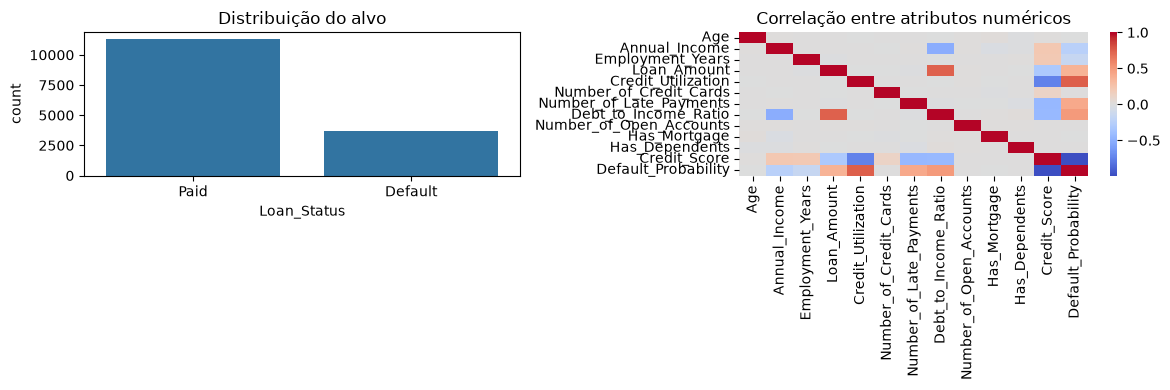

In [3]:
display(df.describe().T)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x=TARGET, ax=axes[0])
axes[0].set_title('Distribuição do alvo')
sns.heatmap(df.select_dtypes(include='number').corr(), cmap='coolwarm', center=0, ax=axes[1])
axes[1].set_title('Correlação entre atributos numéricos')
plt.tight_layout()

A base tem apenas atributos numéricos além do alvo. Por isso, `GaussianNB` é a variante de Naive Bayes escolhida: ela modela atributos contínuos. A imputação mediana fica dentro do pipeline para que cada fold aprenda os valores de imputação exclusivamente nos dados de treino. Não padronizamos: os três estimadores escolhidos não exigem escala comum; no GaussianNB, a busca ajusta `var_smoothing`.

In [4]:
X = df.drop(columns=[TARGET, 'Default_Probability']).copy()
y = df[TARGET].map({'Default': 1, 'Paid': 0})
if y.isna().any():
    raise ValueError('O alvo contém categorias ausentes ou inesperadas.')
if X.select_dtypes(exclude='number').shape[1]:
    raise ValueError('Há atributos não numéricos; inclua codificação no pré-processamento.')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print('Treino:', X_train.shape, '| Teste:', X_test.shape)
print('Proporção de inadimplência no treino/teste:', round(y_train.mean(), 3), round(y_test.mean(), 3))

Treino: (12000, 12) | Teste: (3000, 12)
Proporção de inadimplência no treino/teste: 0.247 0.247


## 3. Protocolo e modelos

A divisão estratificada 80/20 é fixa. A validação cruzada estratificada com cinco folds e a busca de hiperparâmetros usam somente o treino. O conjunto de teste será usado ao final para comparar os seis modelos. O pipeline contém a imputação e o classificador, evitando que a validação veja estatísticas calculadas fora do fold.

In [5]:
model_specs = {
    'Naive Bayes (baseline)': (GaussianNB(), {}),
    'Naive Bayes (ajustado)': (GaussianNB(), {'model__var_smoothing': np.logspace(-12, -6, 7)}),
    'Árvore (baseline)': (DecisionTreeClassifier(random_state=SEED), {}),
    'Árvore (ajustada)': (DecisionTreeClassifier(random_state=SEED), {
        'model__criterion': ['gini', 'entropy'],
        'model__max_depth': [5, 10, None],
        'model__min_samples_leaf': [1, 5, 20],
    }),
    'Random Forest (baseline)': (RandomForestClassifier(random_state=SEED, n_jobs=1), {}),
    'Random Forest (ajustada)': (RandomForestClassifier(random_state=SEED, n_jobs=1), {
        'model__n_estimators': [100, 200],
        'model__max_depth': [None, 10],
        'model__max_features': ['sqrt'],
        'model__min_samples_leaf': [1],
    }),
}

def make_pipeline(estimator):
    return Pipeline([('imputer', SimpleImputer(strategy='median')), ('model', estimator)])

scoring = {'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall', 'f1': 'f1', 'roc_auc': 'roc_auc'}

## 4. Validação cruzada e ajuste

A métrica principal da busca é F1 da classe `Default`, equilibrando precisão e revocação. Para cada configuração, registramos média, desvio-padrão entre folds e tempo de ajuste. O tempo depende do hardware e não deve ser interpretado como uma medida universal.

In [6]:
results = {}
cv_rows = []
for name, (estimator, param_grid) in model_specs.items():
    pipe = make_pipeline(estimator)
    start = time.perf_counter()
    if param_grid:
        fitted = GridSearchCV(pipe, param_grid, scoring='f1', cv=cv, n_jobs=1, refit=True)
        fitted.fit(X_train, y_train)
        model = fitted.best_estimator_
        best_params = fitted.best_params_
        best_f1 = fitted.best_score_
        fold_scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    else:
        model = pipe
        fold_scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
        model.fit(X_train, y_train)
        best_params = {}
        best_f1 = fold_scores['test_f1'].mean()
    elapsed = time.perf_counter() - start
    results[name] = {'model': model, 'params': best_params, 'cv': fold_scores, 'fit_seconds': elapsed}
    row = {'modelo': name, 'F1 CV (média)': fold_scores['test_f1'].mean(), 'F1 CV (DP)': fold_scores['test_f1'].std(), 'tempo (s)': elapsed, 'melhores parâmetros': best_params}
    cv_rows.append(row)
cv_table = pd.DataFrame(cv_rows).set_index('modelo')
display(cv_table)

,F1 CV (média),F1 CV (DP),tempo (s),melhores parâmetros
modelo,,,,
Naive Bayes (baseline),0.898967,0.005160,0.779111,{}
Naive Bayes (ajustado),0.937334,0.006697,2.367909,{'model__var_smoothing': 1e-11}
Árvore (baseline),0.962213,0.004186,0.789031,{}
Árvore (ajustada),0.964217,0.004640,9.589676,"{'model__criterion': 'entropy', 'model__max_de..."
Random Forest (baseline),0.970546,0.005338,10.912208,{}
Random Forest (ajustada),0.972104,0.005781,68.691411,"{'model__max_depth': None, 'model__max_feature..."


## 5. Avaliação final no teste

Agora, cada um dos seis modelos é avaliado na mesma partição de teste. O relatório por classe e as matrizes de confusão detalham falsos negativos e falsos positivos. Em concessão de crédito, falso negativo (inadimplente classificado como pago) pode representar perda financeira; falso positivo (pagador recusado) também tem custo para o cliente e a instituição. O limiar padrão de 0,5 e o custo relativo dos erros devem ser discutidos como limitações.

In [7]:
test_rows = []
test_predictions = {}
for name, result in results.items():
    model = result['model']
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    test_predictions[name] = (pred, prob)
    test_rows.append({
        'modelo': name,
        'acurácia': accuracy_score(y_test, pred),
        'precisão Default': precision_score(y_test, pred, zero_division=0),
        'revocação Default': recall_score(y_test, pred, zero_division=0),
        'F1 Default': f1_score(y_test, pred, zero_division=0),
        'AUC ROC': roc_auc_score(y_test, prob),
        'tempo treino (s)': result['fit_seconds'],
    })
test_table = pd.DataFrame(test_rows).set_index('modelo')
comparison = cv_table[['F1 CV (média)', 'F1 CV (DP)']].join(test_table)
display(comparison.sort_values('F1 Default', ascending=False).round(4))

,F1 CV (média),F1 CV (DP),acurácia,precisão Default,revocação Default,F1 Default,AUC ROC,tempo treino (s)
modelo,,,,,,,,
Random Forest (baseline),0.9705,0.0053,0.989,0.9836,0.9716,0.9776,0.9994,10.9122
Random Forest (ajustada),0.9721,0.0058,0.989,0.9849,0.9703,0.9775,0.9995,68.6914
Árvore (ajustada),0.9642,0.0046,0.987,0.9730,0.9743,0.9737,0.9860,9.5897
Árvore (baseline),0.9622,0.0042,0.984,0.9676,0.9676,0.9676,0.9785,0.7890
Naive Bayes (ajustado),0.9373,0.0067,0.970,0.9221,0.9595,0.9404,0.9954,2.3679
Naive Bayes (baseline),0.8990,0.0052,0.952,0.9269,0.8743,0.8999,0.9918,0.7791


In [8]:
for algorithm, baseline, tuned in [('Naive Bayes', 'Naive Bayes (baseline)', 'Naive Bayes (ajustado)'), ('Árvore', 'Árvore (baseline)', 'Árvore (ajustada)'), ('Random Forest', 'Random Forest (baseline)', 'Random Forest (ajustada)')]:
    cv_gain = comparison.loc[tuned, 'F1 CV (média)'] - comparison.loc[baseline, 'F1 CV (média)']
    test_gain = comparison.loc[tuned, 'F1 Default'] - comparison.loc[baseline, 'F1 Default']
    print(f'{algorithm}: ajuste alterou o F1 médio CV em {cv_gain:+.3f} e o F1 de teste em {test_gain:+.3f}.')
best = comparison['F1 Default'].idxmax()
print(f'F1 de teste mais alto nesta divisão: {best} ({comparison.loc[best, "F1 Default"]:.3f}). Compare também precisão, revocação, estabilidade CV e tempo antes de recomendar esse modelo.')

Naive Bayes: ajuste alterou o F1 médio CV em +0.038 e o F1 de teste em +0.041.
Árvore: ajuste alterou o F1 médio CV em +0.002 e o F1 de teste em +0.006.
Random Forest: ajuste alterou o F1 médio CV em +0.002 e o F1 de teste em -0.000.
F1 de teste mais alto nesta divisão: Random Forest (baseline) (0.978). Compare também precisão, revocação, estabilidade CV e tempo antes de recomendar esse modelo.


--- Naive Bayes (baseline) ---
              precision    recall  f1-score   support

        Paid       0.96      0.98      0.97      2260
     Default       0.93      0.87      0.90       740

    accuracy                           0.95      3000
   macro avg       0.94      0.93      0.93      3000
weighted avg       0.95      0.95      0.95      3000

--- Naive Bayes (ajustado) ---
              precision    recall  f1-score   support

        Paid       0.99      0.97      0.98      2260
     Default       0.92      0.96      0.94       740

    accuracy                           0.97      3000
   macro avg       0.95      0.97      0.96      3000
weighted avg       0.97      0.97      0.97      3000

--- Árvore (baseline) ---
              precision    recall  f1-score   support

        Paid       0.99      0.99      0.99      2260
     Default       0.97      0.97      0.97       740

    accuracy                           0.98      3000
   macro avg       0.98      0.98      0

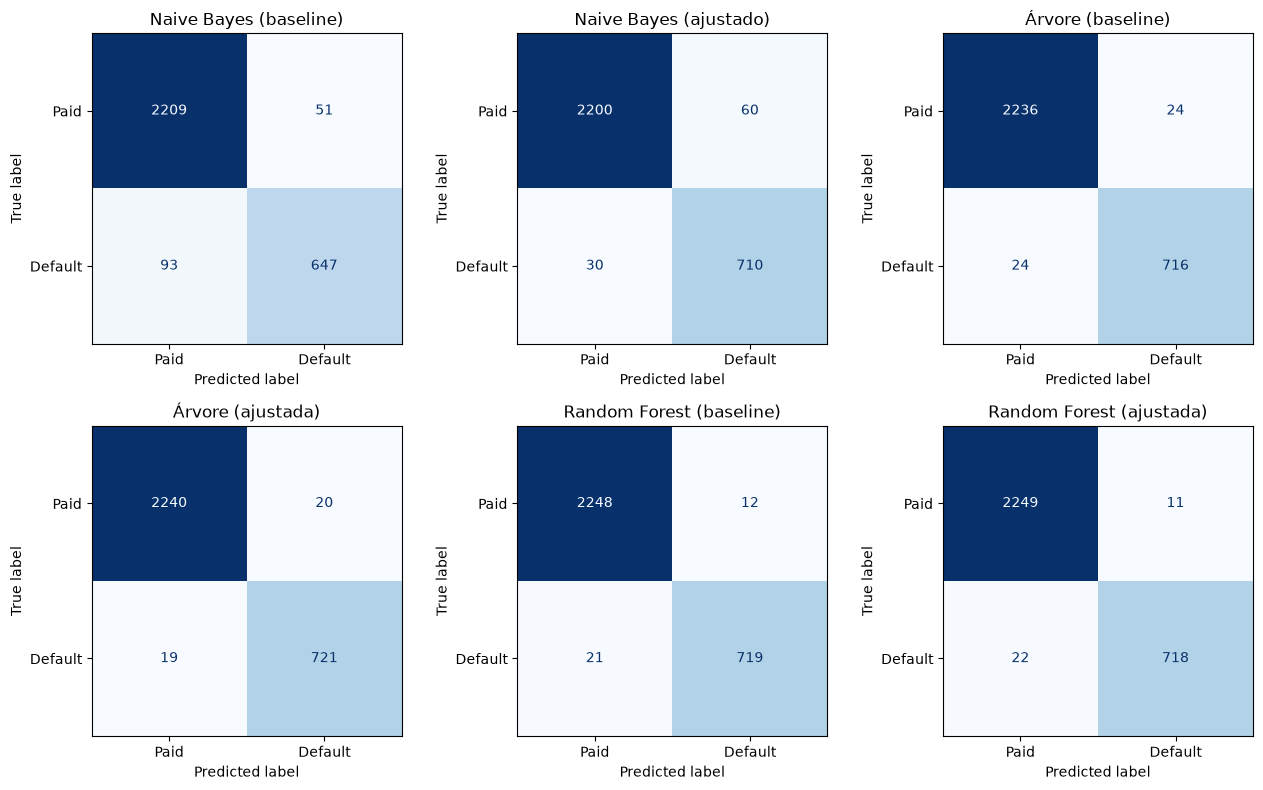

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (name, (pred, _)) in zip(axes.flat, test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Paid', 'Default'], cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()

for name, (pred, _) in test_predictions.items():
    print(f'--- {name} ---')
    print(classification_report(y_test, pred, target_names=['Paid', 'Default'], zero_division=0))

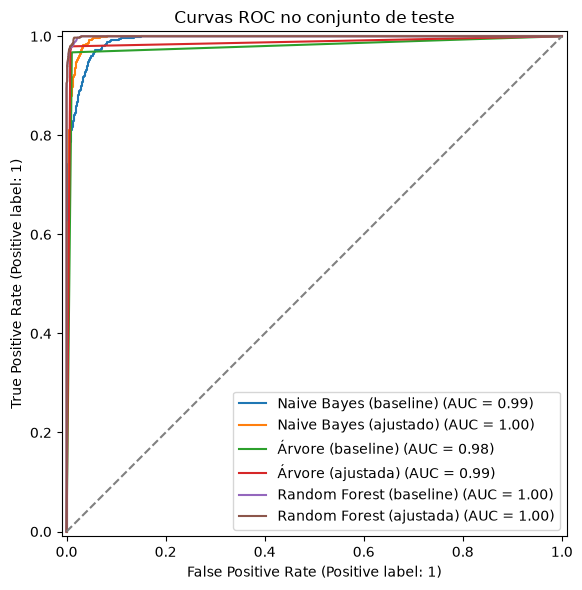

In [10]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, (pred, prob) in test_predictions.items():
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle='--', color='gray')
ax.set_title('Curvas ROC no conjunto de teste')
plt.tight_layout()

## 6. Interpretabilidade e importância dos atributos

A árvore ajustada é exibida com profundidade limitada para leitura; a limitação visual não altera o modelo avaliado. A importância por impureza da Random Forest é uma indicação exploratória, não causal, e pode favorecer variáveis contínuas ou correlacionadas.

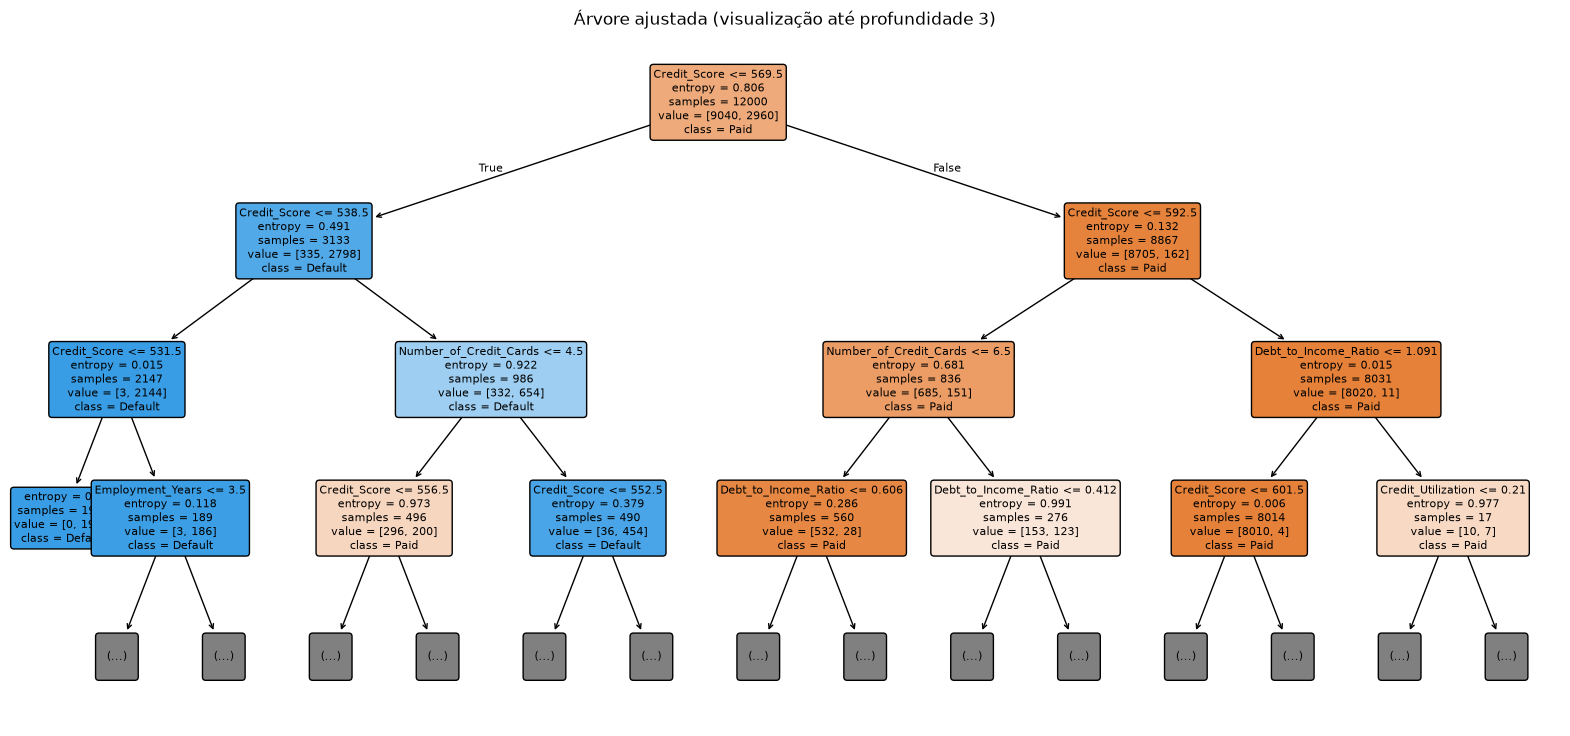

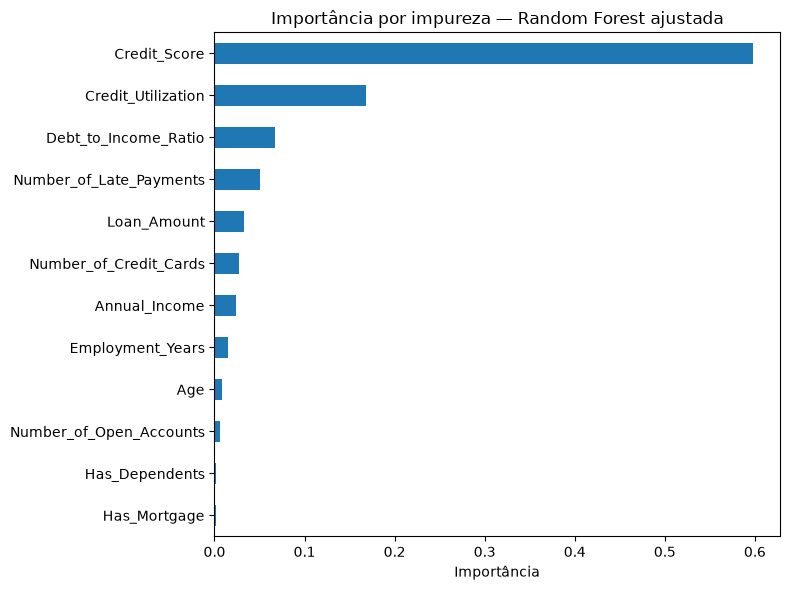

In [11]:
tree_model = results['Árvore (ajustada)']['model'].named_steps['model']
plt.figure(figsize=(20, 9))
plot_tree(tree_model, feature_names=X.columns, class_names=['Paid', 'Default'], filled=True, rounded=True, max_depth=3, fontsize=8)
plt.title('Árvore ajustada (visualização até profundidade 3)')
plt.show()

forest_model = results['Random Forest (ajustada)']['model'].named_steps['model']
importances = pd.Series(forest_model.feature_importances_, index=X.columns).sort_values()
importances.tail(12).plot.barh(figsize=(8, 6), title='Importância por impureza — Random Forest ajustada')
plt.xlabel('Importância')
plt.tight_layout()

## 7. Discussão e conclusão

A tabela e os gráficos acima mostram os resultados desta execução. A célula seguinte resume as diferenças entre baseline e ajustado usando F1 da classe `Default`. Considere o desvio-padrão da validação cruzada ao julgar ganhos pequenos; folds próximos não constituem um teste estatístico independente.

Neste problema, falso negativo (inadimplente classificado como pago) pode representar perda financeira; falso positivo (pagador recusado) também tem custo para o cliente e a instituição. O limiar padrão de 0,5 não pondera esses custos.

**Limitações:** a base foi obtida no Kaggle (Chaitanya Jamble, URL indicada no início do notebook), mas o método de geração e a representatividade não estão documentados; a análise depende de uma divisão treino/teste; o limiar não foi otimizado por custo; `Default_Probability` foi excluída por sua forte associação com o alvo e origem não documentada, mas a exclusão pode descartar sinal legítimo. Mesmo sem esse atributo, os resultados são altos e devem ser tratados com cautela até compreender melhor o processo de geração e confirmar a representatividade. Não generalize para decisões reais de crédito sem validação externa.
